# Регрессия зарплат на датасете LinkedIn Job Postings (2023–2024)

## Пункт 0. Описание задачи

**Задача:** регрессия — по характеристикам вакансии предсказать годовую зарплату. Такая модель может подсказать работодателю адекватную зарплатную вилку, а соискателю — оценить, насколько щедрое предложение.

**Целевой признак:** `normalized_salary` — зарплата, приведённая платформой к годовой сумме в долларах (например, \$25/час → \$52 000/год). Благодаря этому почасовые и годовые вакансии можно сравнивать между собой.

**Данные:** [LinkedIn Job Postings](https://www.kaggle.com/datasets/arshkon/linkedin-job-postings) — ~124 тыс. вакансий на LinkedIn за 2023–2024 гг. Зарплата указана примерно в 30% из них (~36 тыс.) — они и составляют выборку. Признаки:
- **условия работы** — тип занятости (полная, частичная, контракт…), уровень опыта, удалёнка, период оплаты (почасовая / годовая);
- **география** — штат (извлекаем из поля `location`);
- **профессиональная область** — навыки вакансии (IT, Sales, Engineering… — 35 категорий) и флаги Senior / Manager в названии;
- **работодатель** — размер компании, число сотрудников и подписчиков, число бенефитов;
- **публикация** — просмотры, отклики, способ подачи заявки, длина описания.

**План:** EDA → очистка выбросов и пропусков → кодирование и масштабирование → $k$-NN с подбором $k$ → сравнение с другими моделями и дополнительные эксперименты.

# Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 50)


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

## Пункт 1. Прочитать данные

Читаем основную таблицу `postings.csv`, смотрим её размер и первые строки. Затем присоединяем вспомогательные таблицы датасета — в них есть полезная информация, которой нет в основной:
- `job_skills.csv` → бинарные столбцы `skill_*` (1 — навык указан в вакансии; у одной вакансии их может быть несколько);
- `benefits.csv` → число бенефитов `n_benefits` (страховка, отпуск и т.п.);
- `companies.csv`, `employee_counts.csv` → размер компании, число сотрудников и подписчиков на LinkedIn (берём последний замер).

In [2]:
# Путь к распакованному архиву датасета.
# Если запускаете в Kaggle: DATA_DIR = '../input/linkedin-job-postings/'
DATA_DIR = '/home/naitora/Downloads/archive/'

df_raw = pd.read_csv(DATA_DIR + 'postings.csv')
print(f"Размерность исходного датасета: {df_raw.shape}")
display(df_raw.head())

# --- Навыки вакансии: multi-hot кодирование ---
job_skills = pd.read_csv(DATA_DIR + 'jobs/job_skills.csv')
skills_wide = pd.crosstab(job_skills['job_id'], job_skills['skill_abr']).clip(upper=1).add_prefix('skill_')

# --- Количество бенефитов ---
n_benefits = pd.read_csv(DATA_DIR + 'jobs/benefits.csv').groupby('job_id').size().rename('n_benefits')

# --- Характеристики компаний ---
companies = pd.read_csv(DATA_DIR + 'companies/companies.csv', usecols=['company_id', 'company_size'])
emp_counts = (pd.read_csv(DATA_DIR + 'companies/employee_counts.csv')
                .sort_values('time_recorded')
                .drop_duplicates('company_id', keep='last')
                [['company_id', 'employee_count', 'follower_count']])

df_full = (df_raw
           .merge(companies, on='company_id', how='left')
           .merge(emp_counts, on='company_id', how='left')
           .merge(n_benefits, left_on='job_id', right_index=True, how='left')
           .merge(skills_wide, left_on='job_id', right_index=True, how='left'))

print(f"Размерность после присоединения вспомогательных таблиц: {df_full.shape}")
print(f"Вакансий с указанной зарплатой: {df_full['normalized_salary'].notna().sum()}")

Размерность исходного датасета: (123849, 31)


,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,min_salary,formatted_work_type,applies,original_listed_time,remote_allowed,job_posting_url,application_url,application_type,expiry,closed_time,formatted_experience_level,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,17.0,Full-time,2.0,1.713398e+12,NaN,https://www.linkedin.com/jobs/view/921716/?trk...,NaN,ComplexOnsiteApply,1.715990e+12,NaN,NaN,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,30.0,Full-time,NaN,1.712858e+12,NaN,https://www.linkedin.com/jobs/view/1829192/?tr...,NaN,ComplexOnsiteApply,1.715450e+12,NaN,NaN,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,45000.0,Full-time,NaN,1.713278e+12,NaN,https://www.linkedin.com/jobs/view/10998357/?t...,NaN,ComplexOnsiteApply,1.715870e+12,NaN,NaN,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,140000.0,Full-time,NaN,1.712896e+12,NaN,https://www.linkedin.com/jobs/view/23221523/?t...,NaN,ComplexOnsiteApply,1.715488e+12,NaN,NaN,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,60000.0,Full-time,NaN,1.713452e+12,NaN,https://www.linkedin.com/jobs/view/35982263/?t...,NaN,ComplexOnsiteApply,1.716044e+12,NaN,NaN,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


Размерность после присоединения вспомогательных таблиц: (123849, 70)
Вакансий с указанной зарплатой: 36073


## Пункт 2. Разбиение на обучающую и тестовую выборки

Перед разбиением готовим таблицу:
- Оставляем вакансии с указанной зарплатой в USD (других валют единицы).
- Создаём признаки из текстовых полей: `state` (штат из `location`, например `"New York, NY"` → `NY`), `title_senior` / `title_manager` (ключевые слова в названии), `desc_len` (длина описания), `posting_days` (срок жизни вакансии в днях).
- Удаляем ID, ссылки и сырой текст — без NLP-обработки модели их не используют. Также удаляем константные и дублирующие столбцы.
- **Удаляем `min_salary`, `max_salary`, `med_salary`** — из них вычислен целевой признак. Если их оставить, модель просто «подсмотрит» ответ (утечка целевой переменной).

Делим выборку на train и test в пропорции 80 / 20 с фиксированным `random_state=42` для воспроизводимости. Все дальнейшие решения (границы выбросов, медианы, параметры масштабирования) принимаем только по train.

In [3]:
df = df_full[df_full['normalized_salary'].notna() & (df_full['currency'] == 'USD')].copy()

# --- Feature engineering из сырых полей ---
df['state'] = df['location'].str.extract(r',\s*([A-Z]{2})$')[0]
df.loc[df['location'] == 'United States', 'state'] = 'US'
df['state'] = df['state'].fillna('Other')

title = df['title'].str.lower()
df['title_senior'] = title.str.contains(r'\b(?:senior|sr\.?|lead|principal|staff)\b').astype(int)
df['title_manager'] = title.str.contains(r'\b(?:manager|director|head|vp|vice president|chief)\b').astype(int)

df['desc_len'] = df['description'].fillna('').str.len()
df['posting_days'] = (df['expiry'] - df['listed_time']) / (1000 * 60 * 60 * 24)

cols_to_drop = ['job_id', 'company_id', 'company_name', 'title', 'description', 'skills_desc', 'location',
                'job_posting_url', 'application_url', 'posting_domain', 'zip_code', 'fips',
                'max_salary', 'min_salary', 'med_salary',                       # утечка целевой переменной
                'currency', 'compensation_type', 'sponsored', 'work_type',      # константы / дубликаты
                'closed_time', 'original_listed_time', 'listed_time', 'expiry']
df = df.drop(columns=cols_to_drop)

X = df.drop(columns=['normalized_salary'])
y = df['normalized_salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Обучающая выборка: {X_train.shape}, Тестовая выборка: {X_test.shape}")

Обучающая выборка: (28846, 51), Тестовая выборка: (7212, 51)


## Пункт 3. Визуализация и основные характеристики

Считаем основные статистики (`describe()`: среднее, разброс, квартили), строим корреляционные матрицы, распределение зарплаты и её зависимость от ключевых категорий — уровня опыта, периода оплаты и навыков.

Кроме корреляции Пирсона считаем корреляцию **Спирмена** — это та же корреляция, но посчитанная по рангам значений. Она устойчива к выбросам и улавливает любую монотонную зависимость, а не только линейную.

Статистические характеристики числовых признаков (X_train):


,count,mean,std,min,25%,50%,75%,max
views,28449.0,19.778551,1.298402e+02,1.000000,3.0,5.0,10.0,9.975000e+03
applies,7043.0,11.668465,3.138482e+01,1.000000,1.0,3.0,9.0,7.290000e+02
remote_allowed,3894.0,1.000000,0.000000e+00,1.000000,1.0,1.0,1.0,1.000000e+00
company_size,27018.0,4.706159,2.106628e+00,1.000000,3.0,5.0,7.0,7.000000e+00
employee_count,28445.0,17346.269749,6.097672e+04,0.000000,145.0,1334.0,10027.0,7.483120e+05
follower_count,28445.0,696968.119423,2.869884e+06,0.000000,12422.0,62285.0,272833.0,3.270284e+07
n_benefits,8466.0,2.460666,1.910255e+00,1.000000,1.0,2.0,3.0,1.200000e+01
desc_len,28846.0,3920.726444,2.289498e+03,0.000000,2190.0,3533.0,5252.0,2.182900e+04
posting_days,28846.0,37.139299,3.213074e+01,6.999537,30.0,30.0,30.0,1.800494e+02
title_senior,28846.0,0.142550,3.496195e-01,0.000000,0.0,0.0,0.0,1.000000e+00


Статистика целевой переменной y_train (normalized_salary):


count         28,846.00
mean         195,469.38
std        4,878,459.03
min                0.00
25%           51,500.20
50%           81,575.00
75%          125,000.00
max      535,600,000.00
Name: normalized_salary, dtype: str

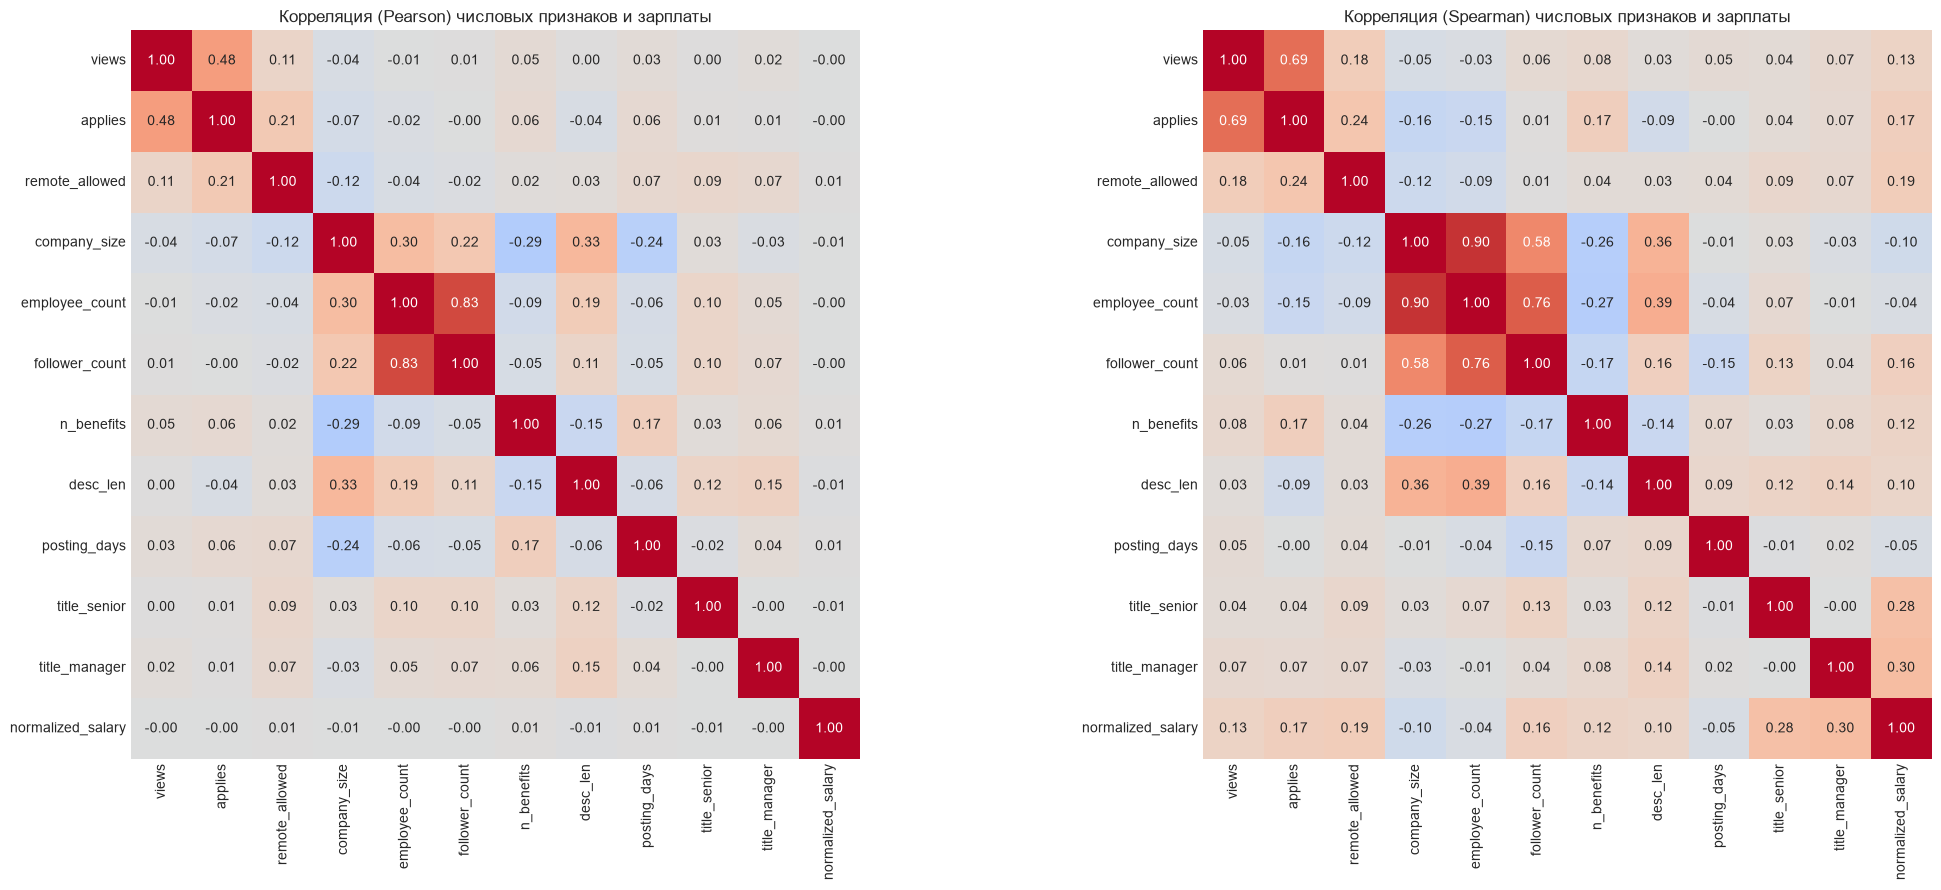

Нулевых зарплат: 13, меньше $10 тыс./год: 329, больше $1 млн/год: 28


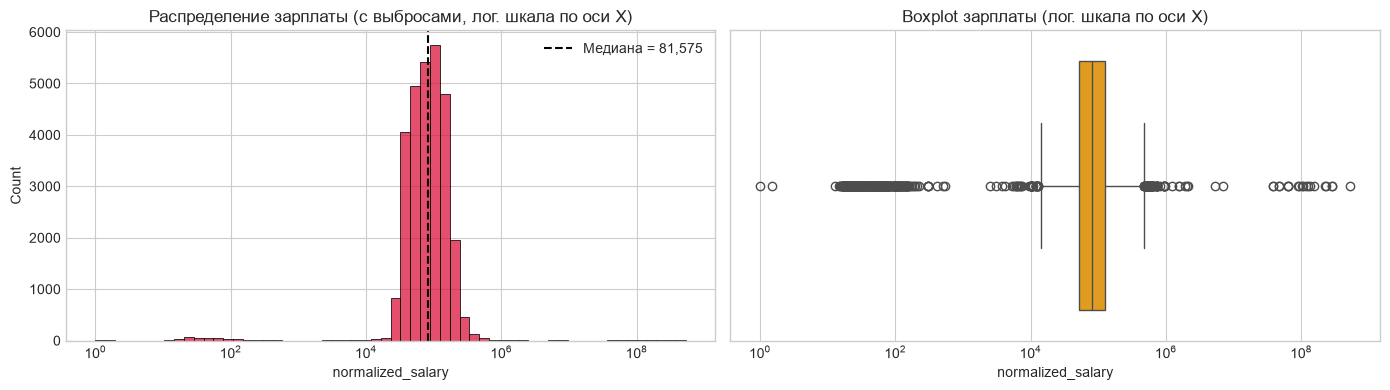

In [4]:
num_features = ['views', 'applies', 'remote_allowed', 'company_size', 'employee_count', 'follower_count',
                'n_benefits', 'desc_len', 'posting_days', 'title_senior', 'title_manager']

print("Статистические характеристики числовых признаков (X_train):")
display(X_train[num_features].describe().T)

print("Статистика целевой переменной y_train (normalized_salary):")
display(y_train.describe().apply(lambda v: f"{v:,.2f}"))

# Для EDA: отсутствие значения в remote_allowed / applies означает 0 (подробнее в пункте 5)
eda_num = pd.concat([X_train[num_features], y_train], axis=1)
eda_num[['remote_allowed', 'applies']] = eda_num[['remote_allowed', 'applies']].fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, method in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(eda_num.corr(method=method), annot=True, fmt='.2f', cmap='coolwarm', square=True,
                vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"Корреляция ({method.capitalize()}) числовых признаков и зарплаты")
plt.tight_layout()
plt.show()

# Значения зарплаты охватывают 8 порядков (от десятков долларов до сотен миллионов),
# поэтому на линейной оси всё сливается в один столбик — используем логарифмическую шкалу по X
y_pos = y_train[y_train > 0]
print(f"Нулевых зарплат: {(y_train <= 0).sum()}, "
      f"меньше $10 тыс./год: {(y_pos < 1e4).sum()}, больше $1 млн/год: {(y_pos > 1e6).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(y_pos, bins=60, color='crimson', log_scale=True, ax=axes[0])
axes[0].axvline(y_train.median(), color='black', linestyle='--', label=f'Медиана = {y_train.median():,.0f}')
axes[0].set_title("Распределение зарплаты (с выбросами, лог. шкала по оси X)")
axes[0].legend()

sns.boxplot(x=y_pos, color='orange', log_scale=True, ax=axes[1])
axes[1].set_title("Boxplot зарплаты (лог. шкала по оси X)")
plt.tight_layout()
plt.show()

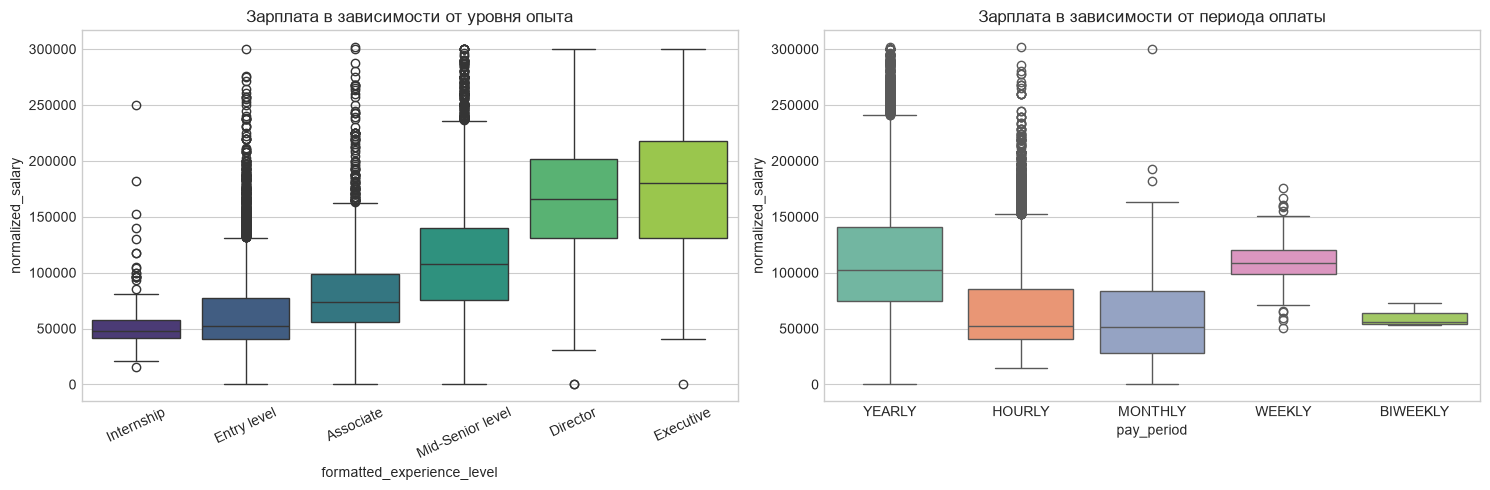

Количество вакансий по периоду оплаты:


pay_period
YEARLY      16518
HOURLY      11771
MONTHLY       417
WEEKLY        132
BIWEEKLY        8
Name: count, dtype: int64

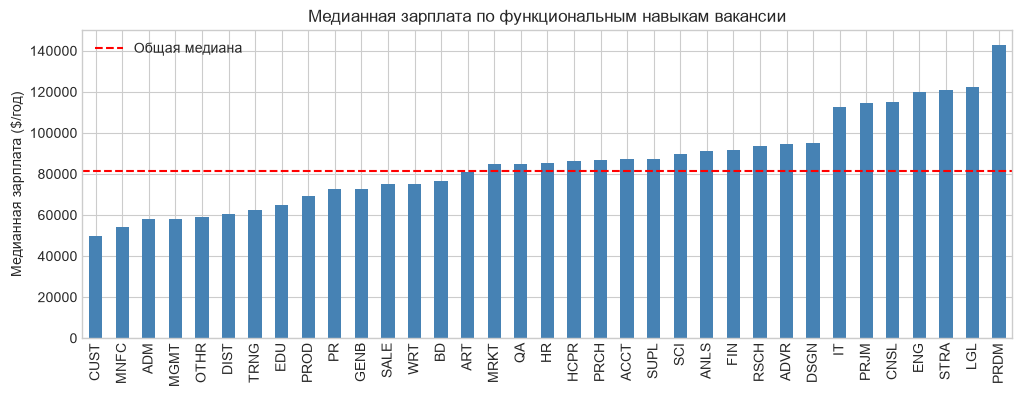

In [5]:
# Зарплата по категориям (в пределах 1-99 перцентилей, чтобы выбросы не сжимали график)
eda = pd.concat([X_train, y_train], axis=1)
eda = eda[eda['normalized_salary'].between(*y_train.quantile([0.01, 0.99]))]

exp_order = ['Internship', 'Entry level', 'Associate', 'Mid-Senior level', 'Director', 'Executive']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=eda, x='formatted_experience_level', y='normalized_salary', order=exp_order,
            palette='viridis', ax=axes[0])
axes[0].set_title('Зарплата в зависимости от уровня опыта')
axes[0].tick_params(axis='x', rotation=25)

sns.boxplot(data=eda, x='pay_period', y='normalized_salary', palette='Set2', ax=axes[1],
            order=eda['pay_period'].value_counts().index)
axes[1].set_title('Зарплата в зависимости от периода оплаты')
plt.tight_layout()
plt.show()

print("Количество вакансий по периоду оплаты:")
display(X_train['pay_period'].value_counts())

skill_cols = [c for c in X_train.columns if c.startswith('skill_')]
skill_median = {c.replace('skill_', ''): y_train[X_train[c] == 1].median() for c in skill_cols}
skill_median = pd.Series(skill_median).sort_values()
plt.figure(figsize=(12, 4))
skill_median.plot(kind='bar', color='steelblue')
plt.axhline(y_train.median(), color='red', linestyle='--', label='Общая медиана')
plt.title('Медианная зарплата по функциональным навыкам вакансии')
plt.ylabel('Медианная зарплата ($/год)')
plt.legend()
plt.show()

**Интерпретация:**
- **Зарплата сильно скошена вправо и содержит ошибки.** Медиана — \$81.6 тыс., а среднее — \$195 тыс. из-за значений до \$535 млн/год. На линейной шкале всё сливается в один столбик, поэтому используем логарифмическую. На ней видны основной «колокол» и два хвоста ошибок: ~330 зарплат меньше \$10 тыс./год (почасовые ставки, помеченные как годовые), 28 — больше \$1 млн и ещё 13 нулевых.
- **Пирсон не видит связей** ($|r| \le 0.01$): несколько огромных ошибочных значений полностью определяют результат. **Спирмен** показывает реальную картину: сильнее всего с зарплатой связаны `title_manager` (0.30), `title_senior` (0.28) и `remote_allowed` (0.19). В целом связи с отдельными числовыми признаками слабые — зарплата больше зависит от категорий.
- **Скоррелированы** показатели размера компании (`company_size`–`employee_count` 0.90, `employee_count`–`follower_count` 0.76) и активности (`views`–`applies` 0.69). К этому вернёмся в пункте 12.
- **Опыт** — самый наглядный фактор: медиана растёт от \$48 тыс. у стажёров до \$108 тыс. на Mid-Senior и \$165–180 тыс. у директоров и топ-менеджеров.
- **Почасовые вакансии** (41% выборки) оплачиваются почти вдвое ниже годовых: \$52 тыс. против \$102 тыс. Обычно это линейный персонал и частичная занятость.
- **По областям:** самые высокие зарплаты — Product Management, юристы, инженеры, IT (> \$110 тыс.); самые низкие — клиентский сервис (\$50 тыс.), производство, администрирование.

## Пункт 4. Выбросы

Выбросы сильно искажают MSE (квадрат ошибки раздувает их вклад) и евклидово расстояние в $k$-NN, поэтому с ними нужно разобраться.

- **Зарплата:** отсекаем значения ниже 2-го и выше 99-го перцентиля обучающей выборки. Как видно в пункте 3, это ошибки ввода, а не реальные редкие зарплаты. Те же границы применяем к тесту — оценивать модель на заведомо неверных ответах бессмысленно.
- **Признаки-счётчики** (`views`, `applies`, `employee_count`, `follower_count`, `desc_len`) имеют длинный хвост: например, есть компании с сотнями тысяч сотрудников. Это реальные значения, поэтому строки не удаляем, а логарифмируем признаки: $\ln(1+x)$. Так гиганты не будут доминировать в расстоянии.

Границы допустимой зарплаты: [26,624; 302,095] $/год
После удаления выбросов: X_train = (27983, 51), X_test = (7009, 51)


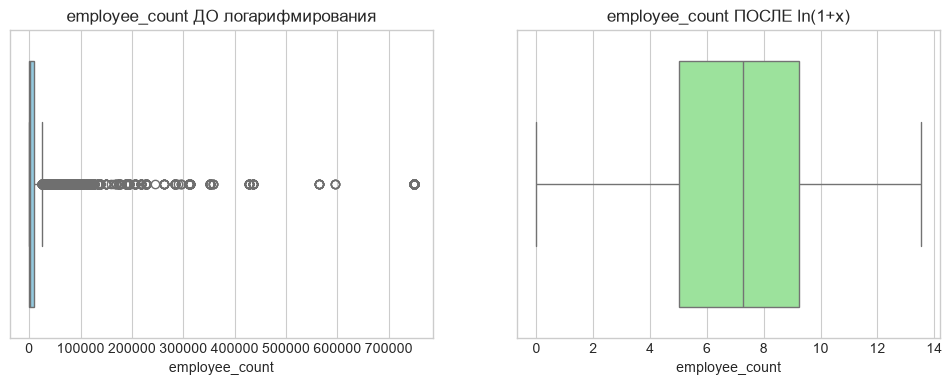

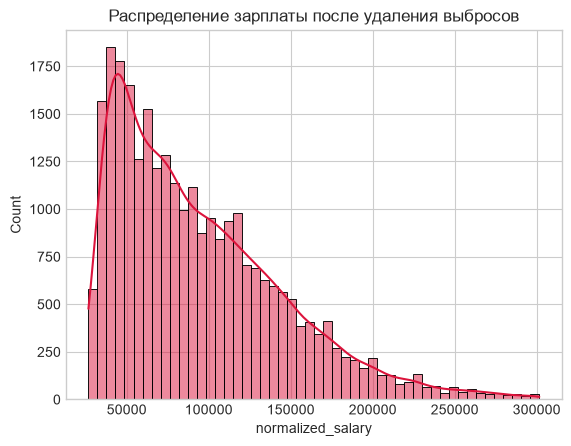

In [6]:
salary_low = y_train.quantile(0.02)
salary_high = y_train.quantile(0.99)
print(f"Границы допустимой зарплаты: [{salary_low:,.0f}; {salary_high:,.0f}] $/год")

mask = (y_train >= salary_low) & (y_train <= salary_high)
X_train = X_train[mask]
y_train = y_train[mask]

test_mask = (y_test >= salary_low) & (y_test <= salary_high)
X_test = X_test[test_mask]
y_test = y_test[test_mask]

print(f"После удаления выбросов: X_train = {X_train.shape}, X_test = {X_test.shape}")

log_cols = ['views', 'applies', 'employee_count', 'follower_count', 'desc_len']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=X_train['employee_count'], ax=axes[0], color='skyblue')
axes[0].set_title('employee_count ДО логарифмирования')
sns.boxplot(x=np.log1p(X_train['employee_count']), ax=axes[1], color='lightgreen')
axes[1].set_title('employee_count ПОСЛЕ ln(1+x)')
plt.show()

for col in log_cols:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

sns.histplot(y_train, bins=50, kde=True, color='crimson')
plt.title("Распределение зарплаты после удаления выбросов")
plt.show()

## Пункт 5. Пропущенные значения

Смотрим, сколько пропусков в каждом столбце, и заполняем их по смыслу признака:
- `remote_allowed`, `applies`, `skill_*`, `n_benefits` → **0**: пропуск здесь означает «нет» или «не указано» (например, `remote_allowed` содержит только единицы, а пустое значение — удалёнки нет);
- `formatted_experience_level` → отдельная категория **`Not specified`**: то, что работодатель не указал уровень, само по себе может быть информативно;
- остальные числовые (данные о компании, `views`) → **медиана**, посчитанная по train. Медиана устойчива к выбросам, а считаем её только по train, чтобы не допустить утечки из теста.

In [7]:
missing = X_train.isnull().sum()
print("Пропуски в X_train:\n", missing[missing > 0].sort_values(ascending=False))

skill_cols = [c for c in X_train.columns if c.startswith('skill_')]
zero_fill = ['remote_allowed', 'applies', 'n_benefits'] + skill_cols
X_train[zero_fill] = X_train[zero_fill].fillna(0)
X_test[zero_fill] = X_test[zero_fill].fillna(0)

X_train['formatted_experience_level'] = X_train['formatted_experience_level'].fillna('Not specified')
X_test['formatted_experience_level'] = X_test['formatted_experience_level'].fillna('Not specified')

num_cols = X_train.select_dtypes(include=[np.number]).columns
for col in num_cols:
    med = X_train[col].median()
    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].fillna(med)

print("\nОсталось пропусков в X_train:", X_train.isnull().sum().sum())
print("Осталось пропусков в X_test:", X_test.isnull().sum().sum())

Пропуски в X_train:
 remote_allowed                24226
applies                       21139
n_benefits                    19705
formatted_experience_level     6250
company_size                   1734
skill_ADM                       399
skill_ACCT                      399
skill_ADVR                      399
skill_BD                        399
skill_ART                       399
skill_ANLS                      399
skill_MNFC                      399
skill_MRKT                      399
skill_OTHR                      399
skill_CNSL                      399
skill_CUST                      399
skill_DIST                      399
skill_DSGN                      399
skill_EDU                       399
skill_ENG                       399
skill_FIN                       399
skill_GENB                      399
skill_HCPR                      399
skill_HR                        399
skill_IT                        399
skill_LGL                       399
skill_MGMT                      399
skill_Q

## Пункт 6. Категориальные признаки

Модели работают с числами, поэтому категориальные признаки `pay_period`, `formatted_work_type`, `formatted_experience_level`, `application_type`, `state` кодируем через **One-Hot Encoding**: каждое значение превращается в отдельный столбец 0/1. Параметр `drop_first=True` убирает один лишний столбец на признак.

Уровень опыта формально порядковый, но в нём есть `Not specified` и `Internship`, которые не встраиваются в единую шкалу, поэтому тоже кодируем через One-Hot. Столбцы теста выравниваем по train.

In [8]:
cat_cols = ['pay_period', 'formatted_work_type', 'formatted_experience_level', 'application_type', 'state']

for col in cat_cols:
    print(f"{col}: {X_train[col].nunique()} уникальных значений")

X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print("\nКоличество признаков после One-Hot Encoding:", X_train.shape[1])

pay_period: 5 уникальных значений
formatted_work_type: 7 уникальных значений
formatted_experience_level: 7 уникальных значений
application_type: 4 уникальных значений
state: 53 уникальных значений

Количество признаков после One-Hot Encoding: 117


## Пункт 7. Нормализация

$k$-NN оценивает сходство вакансий по евклидову расстоянию. Без масштабирования признаки с большим диапазоном (например, `posting_days` — десятки дней) подавили бы бинарные признаки навыков и штатов (0/1).

Применяем `StandardScaler` — приводим каждый признак к среднему 0 и стандартному отклонению 1: $z = \frac{x - \mu}{\sigma}$. Параметры $\mu$ и $\sigma$ считаем только по train и применяем к тесту.

In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

display(X_train_scaled.describe().T[['mean', 'std']].head(10).round(3))

,mean,std
views,0.0,1.0
applies,0.0,1.0
remote_allowed,0.0,1.0
company_size,-0.0,1.0
employee_count,-0.0,1.0
follower_count,-0.0,1.0
n_benefits,0.0,1.0
skill_ACCT,0.0,1.0
skill_ADM,0.0,1.0
skill_ADVR,-0.0,1.0


## Пункт 8. Регрессия ближайших соседей

**Почему $k$-NN:** на рынке труда зарплату обычно оценивают по похожим вакансиям — той же области, того же уровня опыта, в том же регионе. $k$-NN делает ровно это: прогноз для вакансии — средняя зарплата $k$ самых похожих на неё вакансий из обучающей выборки. Метод простой, интерпретируемый и не требует предположений о форме зависимости.

Начинаем со стандартного $k = 5$ и считаем метрики $RMSE$, $MAE$ и $R^2$ на train и test.

In [10]:
knn_base = KNeighborsRegressor(n_neighbors=5, n_jobs=-1)

knn_base.fit(X_train_scaled, y_train)

y_train_pred = knn_base.predict(X_train_scaled)
y_test_pred = knn_base.predict(X_test_scaled)

print(f"Базовый kNN (k=5):")
print(f"Train RMSE: {rmse(y_train, y_train_pred):,.0f}, MAE: {mean_absolute_error(y_train, y_train_pred):,.0f}, R2: {r2_score(y_train, y_train_pred):.3f}")
print(f"Test RMSE:  {rmse(y_test, y_test_pred):,.0f}, MAE: {mean_absolute_error(y_test, y_test_pred):,.0f}, R2: {r2_score(y_test, y_test_pred):.3f}")

Базовый kNN (k=5):
Train RMSE: 31,249, MAE: 22,111, R2: 0.627
Test RMSE:  39,269, MAE: 28,487, R2: 0.394


## Пункт 9. Ошибки на train/test и подбор $k$

Перебираем $k$ от 1 до 50 и строим ошибку на train, на кросс-валидации и на тесте. Оптимальное $k$ выбираем по **5-fold кросс-валидации** на train, чтобы не подгонять гиперпараметр под тест; тестовая ошибка — для контроля.

Матрица рассогласования применяется только в классификации, поэтому для регрессии вместо неё строим **график остатков** (ошибка vs прогноз) и **«прогноз vs факт»** — по ним видно, где и как ошибается модель.

k =  1 | Train RMSE =       371 | CV RMSE =    47,692 | Test RMSE =    48,013
k =  3 | Train RMSE =    27,805 | CV RMSE =    40,351 | Test RMSE =    40,856
k =  5 | Train RMSE =    31,249 | CV RMSE =    39,009 | Test RMSE =    39,269
k =  7 | Train RMSE =    32,882 | CV RMSE =    38,578 | Test RMSE =    38,836
k = 10 | Train RMSE =    34,228 | CV RMSE =    38,411 | Test RMSE =    38,665
k = 15 | Train RMSE =    35,487 | CV RMSE =    38,425 | Test RMSE =    38,948
k = 20 | Train RMSE =    36,275 | CV RMSE =    38,639 | Test RMSE =    39,055
k = 25 | Train RMSE =    36,807 | CV RMSE =    38,767 | Test RMSE =    39,296
k = 30 | Train RMSE =    37,233 | CV RMSE =    38,937 | Test RMSE =    39,565
k = 40 | Train RMSE =    37,845 | CV RMSE =    39,181 | Test RMSE =    39,881
k = 50 | Train RMSE =    38,278 | CV RMSE =    39,412 | Test RMSE =    40,115

Оптимальное значение k по кросс-валидации: 11 (CV RMSE: 38,371, Test RMSE: 38,731)


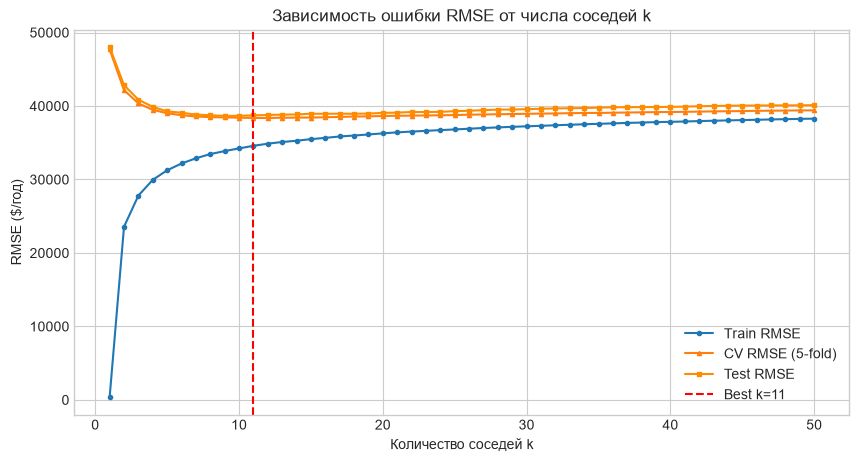

In [11]:
max_k = 50
k_range = list(range(1, max_k + 1))
y_train_arr = y_train.values


def knn_curve(X_fit, y_fit, X_eval, y_eval):
    # RMSE для всех k от 1 до max_k за один поиск соседей
    nn = KNeighborsRegressor(n_neighbors=max_k, n_jobs=-1).fit(X_fit, y_fit)
    _, idx = nn.kneighbors(X_eval)
    cum = np.cumsum(np.asarray(y_fit)[idx], axis=1)
    preds = cum / np.arange(1, max_k + 1)
    return np.sqrt(((preds - np.asarray(y_eval)[:, None]) ** 2).mean(axis=0)), idx


# Ошибка на обучающей выборке (сам объект является своим ближайшим соседом)
train_errors, _ = knn_curve(X_train_scaled, y_train_arr, X_train_scaled, y_train_arr)
# Ошибка на тестовой выборке
test_errors, test_idx = knn_curve(X_train_scaled, y_train_arr, X_test_scaled, y_test.values)

# 5-fold кросс-валидация на train
cv_errors = np.zeros(max_k)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for tr, val in kf.split(X_train_scaled):
    err, _ = knn_curve(X_train_scaled.values[tr], y_train_arr[tr], X_train_scaled.values[val], y_train_arr[val])
    cv_errors += err / kf.get_n_splits()

best_k = k_range[int(np.argmin(cv_errors))]
for k in [1, 3, 5, 7, 10, 15, 20, 25, 30, 40, 50]:
    print(f"k = {k:2d} | Train RMSE = {train_errors[k-1]:>9,.0f} | CV RMSE = {cv_errors[k-1]:>9,.0f} | Test RMSE = {test_errors[k-1]:>9,.0f}")
print(f"\nОптимальное значение k по кросс-валидации: {best_k} "
      f"(CV RMSE: {cv_errors[best_k-1]:,.0f}, Test RMSE: {test_errors[best_k-1]:,.0f})")

plt.figure(figsize=(10, 5))
plt.plot(k_range, train_errors, marker='o', markersize=3, label='Train RMSE')
plt.plot(k_range, cv_errors, marker='^', markersize=3, label='CV RMSE (5-fold)')
plt.plot(k_range, test_errors, marker='s', markersize=3, color='darkorange', label='Test RMSE')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k}')
plt.xlabel('Количество соседей k')
plt.ylabel('RMSE ($/год)')
plt.title('Зависимость ошибки RMSE от числа соседей k')
plt.legend()
plt.show()

k-NN (k=11) на тесте: RMSE = 38,731, MAE = 28,384, R2 = 0.410


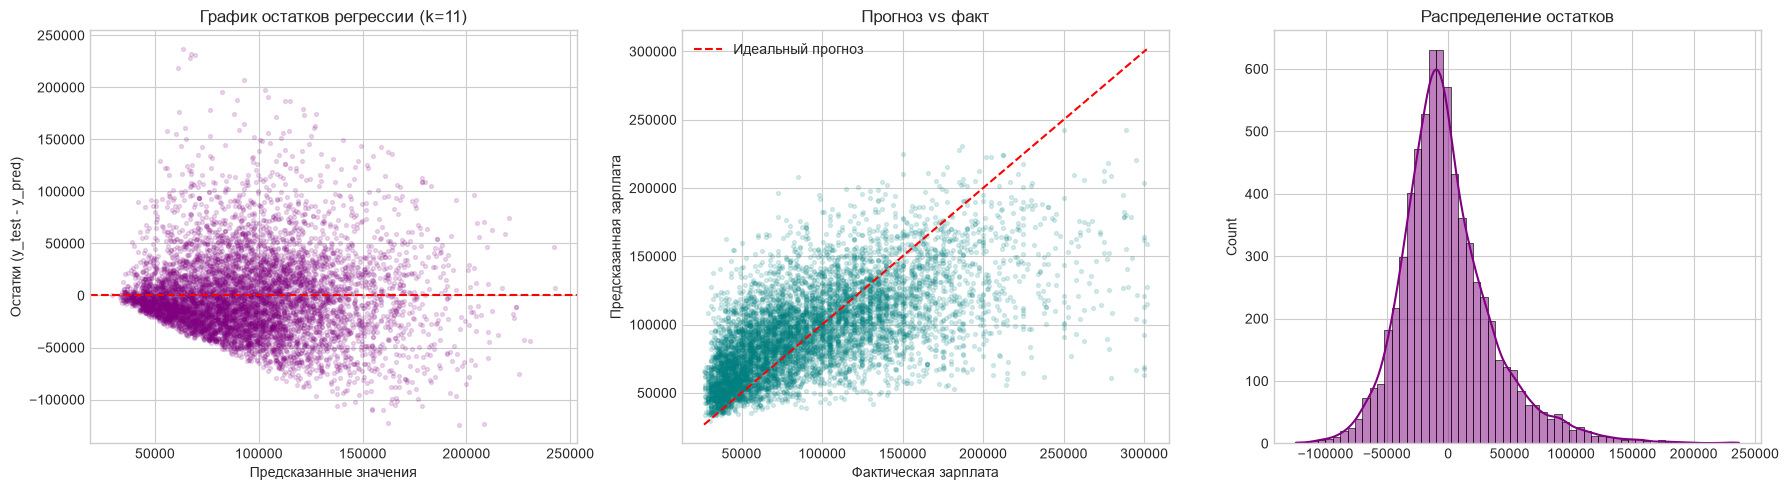

In [12]:
best_pred = y_train_arr[test_idx[:, :best_k]].mean(axis=1)
residuals = y_test.values - best_pred

print(f"k-NN (k={best_k}) на тесте: RMSE = {rmse(y_test, best_pred):,.0f}, "
      f"MAE = {mean_absolute_error(y_test, best_pred):,.0f}, R2 = {r2_score(y_test, best_pred):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(best_pred, residuals, alpha=0.15, color='purple', s=8)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Предсказанные значения')
axes[0].set_ylabel('Остатки (y_test - y_pred)')
axes[0].set_title(f'График остатков регрессии (k={best_k})')

axes[1].scatter(y_test, best_pred, alpha=0.15, color='teal', s=8)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, color='red', linestyle='--', label='Идеальный прогноз')
axes[1].set_xlabel('Фактическая зарплата')
axes[1].set_ylabel('Предсказанная зарплата')
axes[1].set_title('Прогноз vs факт')
axes[1].legend()

sns.histplot(residuals, bins=60, kde=True, color='purple', ax=axes[2])
axes[2].set_title('Распределение остатков')
plt.tight_layout()
plt.show()

**Выводы:**
- $k=1$ — явное переобучение: на train ошибка ≈ 0 (каждая вакансия — сама себе ближайший сосед), на тесте максимальна (\$48 тыс.).
- С ростом $k$ ошибка падает, оптимум — **$k = 11$** (CV RMSE \$38.4 тыс., Test RMSE \$38.7 тыс.). При больших $k$ ошибка медленно растёт — прогноз слишком сглаживается.
- Кривые CV и теста почти совпадают — значит, кросс-валидация надёжно оценивает качество.
- По графикам остатков: ошибки в среднем около нуля, но модель завышает низкие зарплаты и занижает высокие — усреднение по соседям «срезает» крайние значения. Итог: $R^2 = 0.41$, $MAE = \$28.4$ тыс.

## Пункт 10. Другие модели

Сравниваем $k$-NN с другими подходами:
- **константная модель** (всегда медиана) — нижняя граница качества;
- **Ridge-регрессия** — линейная модель: проверяем, хватит ли простой линейной зависимости;
- **случайный лес** и **градиентный бустинг** — ансамбли деревьев, умеют учитывать нелинейности и сочетания признаков (например, «IT + Senior + Калифорния»).

,Train RMSE,Test RMSE,Test MAE,Test R^2
Model,,,,
Dummy (median),52545.294,51719.235,39321.766,-0.051
k-NN (k=11),34579.852,38730.201,28382.947,0.410
Ridge Regression,35933.912,36269.019,26922.853,0.483
Random Forest,19494.200,33771.684,24902.673,0.552
Gradient Boosting,30042.428,33842.692,25087.825,0.550


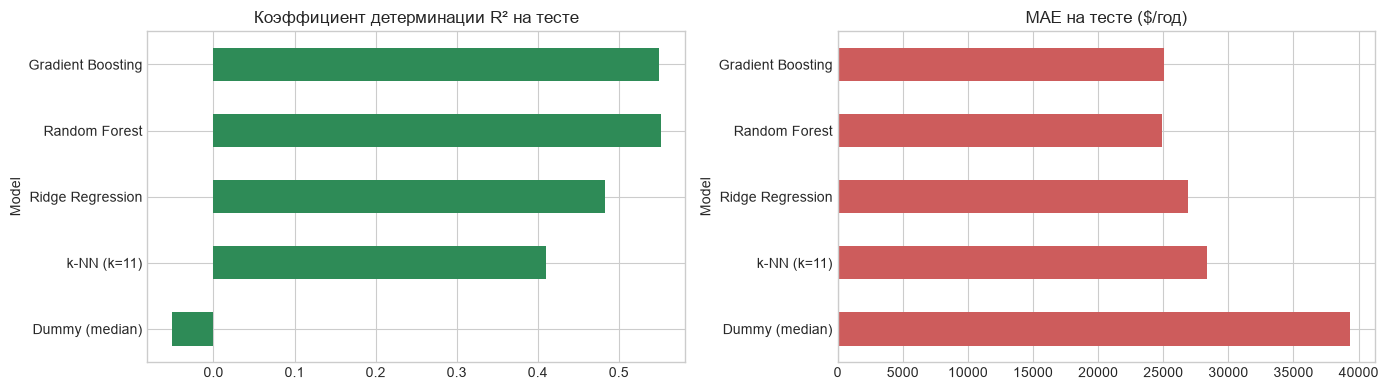

In [13]:
models = {
    "Dummy (median)": DummyRegressor(strategy='median'),
    f"k-NN (k={best_k})": KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42),
}

results = []
fitted = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    fitted[name] = model
    pred_train = model.predict(X_train_scaled)
    pred_test = model.predict(X_test_scaled)

    results.append({
        'Model': name,
        'Train RMSE': rmse(y_train, pred_train),
        'Test RMSE': rmse(y_test, pred_test),
        'Test MAE': mean_absolute_error(y_test, pred_test),
        'Test R^2': r2_score(y_test, pred_test)
    })

df_results = pd.DataFrame(results).set_index('Model')
display(df_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_results['Test R^2'].plot(kind='barh', ax=axes[0], color='seagreen')
axes[0].set_title('Коэффициент детерминации R² на тесте')
df_results['Test MAE'].plot(kind='barh', ax=axes[1], color='indianred')
axes[1].set_title('MAE на тесте ($/год)')
plt.tight_layout()
plt.show()

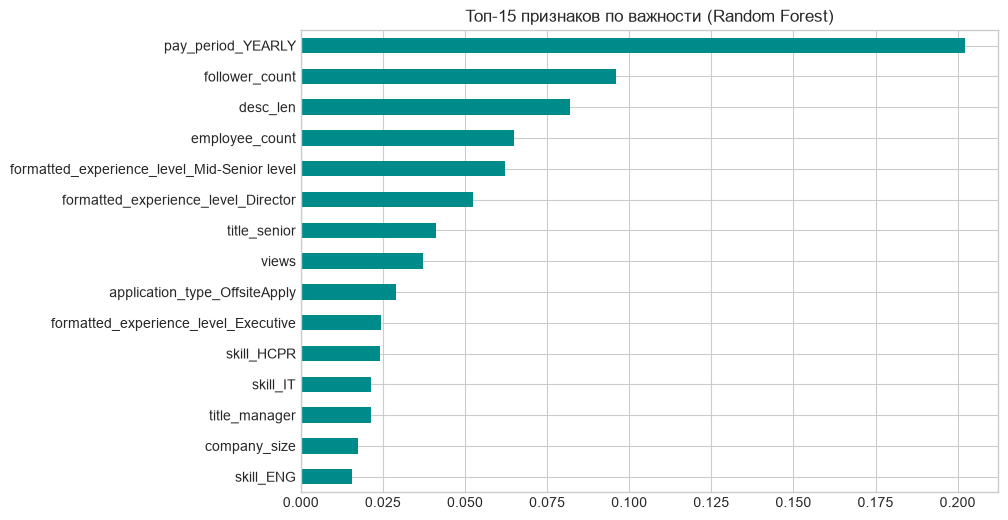

In [14]:
# Важность признаков в случайном лесе — какие факторы сильнее всего определяют зарплату
importances = pd.Series(fitted['Random Forest'].feature_importances_, index=X_train_scaled.columns)
plt.figure(figsize=(9, 6))
importances.sort_values().tail(15).plot(kind='barh', color='darkcyan')
plt.title('Топ-15 признаков по важности (Random Forest)')
plt.show()

**Результаты:**
- Все модели заметно лучше константы ($R^2 = -0.05$).
- **Лучшие — ансамбли деревьев:** Random Forest и бустинг, $R^2 \approx 0.55$, $MAE \approx \$25$ тыс. Лес сильнее переобучается (Train RMSE \$19.5 тыс. против \$33.8 тыс. на тесте), бустинг даёт то же качество с меньшим разрывом.
- **Ridge ($R^2 = 0.48$) обошёл $k$-NN ($0.41$).** После One-Hot у нас 117 признаков, большинство — редкие бинарные (штаты, навыки). В $k$-NN все они весят одинаково и «размывают» расстояние, а Ridge сам подбирает вес каждого признака.
- **Самый важный признак** — годовой период оплаты, далее — данные о компании, длина описания, уровень опыта и флаг Senior.

## Пункт 11. Асимметрия целевой переменной

Классов у нас нет, поэтому аналог дисбаланса классов — сильная асимметрия зарплат: большинство вакансий в диапазоне \$35–130 тыс., а высокие зарплаты образуют длинный хвост.

Обучаем модели на $\ln(1 + y)$ и возвращаем прогноз обратно через $e^{\hat{y}} - 1$. Логарифм выравнивает распределение и уменьшает влияние больших зарплат. Дополнительно смотрим $MAPE$ — среднюю ошибку в процентах, т.к. логарифм оптимизирует именно относительную ошибку.

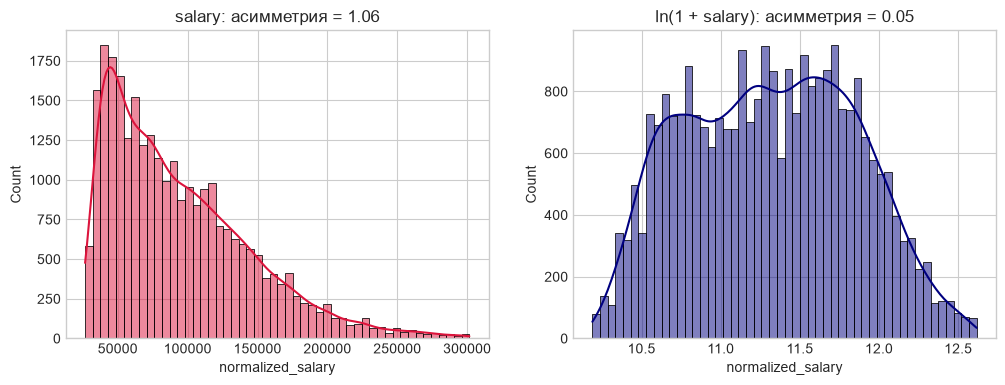

,Test RMSE (исходный y),Test RMSE (log y),Test MAE (исходный y),Test MAE (log y),Test MAPE (исходный y),Test MAPE (log y),Test R^2 (log y)
Model,,,,,,,
k-NN (k=11),38730.201,38991.338,28382.947,27541.823,0.353,0.316,0.402
Ridge Regression,36269.019,36505.095,26922.853,26354.387,0.339,0.318,0.476
Gradient Boosting,33842.692,34011.225,25087.825,24187.477,0.319,0.286,0.545


In [15]:
y_train_log = np.log1p(y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_train, bins=50, kde=True, color='crimson', ax=axes[0])
axes[0].set_title(f'salary: асимметрия = {y_train.skew():.2f}')
sns.histplot(y_train_log, bins=50, kde=True, color='navy', ax=axes[1])
axes[1].set_title(f'ln(1 + salary): асимметрия = {y_train_log.skew():.2f}')
plt.show()

log_results = []
for name in [f"k-NN (k={best_k})", "Ridge Regression", "Gradient Boosting"]:
    model = models[name].__class__(**models[name].get_params())
    model.fit(X_train_scaled, y_train_log)
    pred = np.expm1(model.predict(X_test_scaled))
    log_results.append({
        'Model': name,
        'Test RMSE (исходный y)': df_results.loc[name, 'Test RMSE'],
        'Test RMSE (log y)': rmse(y_test, pred),
        'Test MAE (исходный y)': df_results.loc[name, 'Test MAE'],
        'Test MAE (log y)': mean_absolute_error(y_test, pred),
        'Test MAPE (исходный y)': mean_absolute_percentage_error(y_test, fitted[name].predict(X_test_scaled)),
        'Test MAPE (log y)': mean_absolute_percentage_error(y_test, pred),
        'Test R^2 (log y)': r2_score(y_test, pred),
    })

display(pd.DataFrame(log_results).set_index('Model').round(3))

**Результат:**
- После логарифма распределение почти симметрично (асимметрия 1.06 → 0.05).
- $MAE$ и $MAPE$ снизились у всех моделей: у $k$-NN $MAPE$ 35.3% → 31.6%, у бустинга 31.9% → 28.6%.
- $RMSE$ немного вырос: обратное преобразование слегка занижает высокие зарплаты, а $RMSE$ сильнее всего штрафует именно крупные ошибки.
- Итог: логарифм лучше, если важна относительная ошибка (ошибиться на 10% одинаково плохо при любой зарплате), и хуже, если важна ошибка в долларах.

## Пункт 12. Коррелированные признаки

**Зачем:** сильно скоррелированные признаки несут почти одну и ту же информацию. В $k$-NN такая информация получает двойной вес в расстоянии, в линейных моделях — делает коэффициенты неустойчивыми.

Находим пары с $|r| > 0.7$ и удаляем по одному признаку из каждой. Исключение — dummy-столбцы одного признака (например, `pay_period_HOURLY` / `YEARLY`, $r = -0.97$): их корреляция — артефакт One-Hot (вакансия либо почасовая, либо годовая), а не дублирование. Удаление такого столбца уничтожило бы важнейший признак.

In [16]:
corr = X_train_scaled.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = upper.stack()[lambda s: s > 0.7].sort_values(ascending=False)
print("Все пары признаков с |r| > 0.7:")
display(high_pairs.to_frame('|r|').round(3))


def source_feature(col):
    # Исходный категориальный признак, из которого получен dummy-столбец (или сам столбец)
    return next((c for c in cat_cols if col.startswith(c + '_')), col)


high_pairs = high_pairs[[source_feature(a) != source_feature(b) for a, b in high_pairs.index]]
print("Пары-кандидаты после исключения артефактов One-Hot кодирования:")
display(high_pairs.to_frame('|r|').round(3))

cols_to_remove = sorted({b for (a, b) in high_pairs.index})
print("Исключаемые признаки:", cols_to_remove)

X_train_uncorr = X_train_scaled.drop(columns=cols_to_remove)
X_test_uncorr = X_test_scaled.drop(columns=cols_to_remove)

uncorr_results = []
for name in [f"k-NN (k={best_k})", "Ridge Regression"]:
    model = models[name].__class__(**models[name].get_params())
    model.fit(X_train_uncorr, y_train)
    pred = model.predict(X_test_uncorr)
    uncorr_results.append({
        'Model': name,
        'Test RMSE (все признаки)': df_results.loc[name, 'Test RMSE'],
        'Test RMSE (без коррелир.)': rmse(y_test, pred),
        'Test R^2 (все признаки)': df_results.loc[name, 'Test R^2'],
        'Test R^2 (без коррелир.)': r2_score(y_test, pred),
    })
display(pd.DataFrame(uncorr_results).set_index('Model').round(3))

Все пары признаков с |r| > 0.7:


,,|r|
pay_period_HOURLY,pay_period_YEARLY,0.966
views,applies,0.861
company_size,employee_count,0.790
employee_count,follower_count,0.784
skill_MGMT,skill_MNFC,0.761


Пары-кандидаты после исключения артефактов One-Hot кодирования:


,,|r|
views,applies,0.861
company_size,employee_count,0.790
employee_count,follower_count,0.784
skill_MGMT,skill_MNFC,0.761


Исключаемые признаки: ['applies', 'employee_count', 'follower_count', 'skill_MNFC']


,Test RMSE (все признаки),Test RMSE (без коррелир.),Test R^2 (все признаки),Test R^2 (без коррелир.)
Model,,,,
k-NN (k=11),38730.201,38905.286,0.410,0.405
Ridge Regression,36269.019,37181.113,0.483,0.457


**Результат:**
- Найдены пары `views`–`applies`, `company_size`–`employee_count`, `employee_count`–`follower_count`, `skill_MGMT`–`skill_MNFC`. Удалены `applies`, `employee_count`, `follower_count`, `skill_MNFC`.
- Качество **немного упало**: $k$-NN $R^2$ 0.410 → 0.405, Ridge 0.483 → 0.457. Значит, эти признаки не полные дубликаты: например, `follower_count` отражает узнаваемость бренда и связан с зарплатой, а `employee_count` — почти нет.
- Удаление оправдано только ради упрощения модели, точность оно не повышает.

## Пункт 13. Общие выводы

1. **Данные:** зарплата указана лишь в ~30% вакансий и содержит грубые ошибки (от \$0 до \$535 млн), из-за которых корреляция Пирсона бесполезна — помогла ранговая корреляция Спирмена. Главные факторы зарплаты — период оплаты, уровень опыта, профессиональная область и старшинство позиции.
2. **Предобработка:** ключевые шаги — удаление утечки (`min/max/med_salary`), фильтрация ошибочных зарплат, логарифм признаков-счётчиков, заполнение пропусков по смыслу, One-Hot и стандартизация. Присоединение вспомогательных таблиц (навыки, данные о компании) обогатило признаки.
3. **$k$-NN:** при $k=1$ — переобучение, оптимум по кросс-валидации $k = 11$ ($R^2 = 0.41$, $MAE = \$28.4$ тыс.). Модель завышает низкие и занижает высокие зарплаты.
4. **Сравнение:** лучшие — случайный лес и бустинг ($R^2 \approx 0.55$), т.к. учитывают нелинейности и не зависят от масштаба признаков. Ridge (0.48) обошёл $k$-NN: в пространстве из 117 в основном бинарных признаков расстояние плохо отражает сходство вакансий.
5. **Эксперименты:** логарифм целевой переменной снизил $MAE$ и $MAPE$ ценой небольшого роста $RMSE$; удаление коррелированных признаков качество не улучшило.
6. **Что можно улучшить:** основная информация о вакансии — в тексте (`title`, `description`). Следующий шаг — текстовые признаки (TF-IDF) и отрасль работодателя.